# Semana 1: Python científico y reproducibilidad

**Objetivo:** generar una figura que cualquiera pueda reproducir exactamente: mismos datos,
mismos parámetros y misma semilla aleatoria.

## Modelo

Una señal sinusoidal con ruido gaussiano aditivo:

$$y(t) = \sin(2\pi f t) + \varepsilon(t), \qquad \varepsilon(t) \sim \mathcal{N}(0, \sigma^2)$$

| Parámetro | Valor | Significado |
|---|---|---|
| $f$ | 3 Hz | frecuencia de la señal |
| $\sigma$ | 0.15 | desviación estándar del ruido |
| semilla | 2026 | fija la secuencia pseudoaleatoria |

Un generador `np.random.default_rng(seed)` con la misma semilla produce siempre los mismos
números; sin semilla, cada ejecución es distinta y el resultado no se puede verificar.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from computational_neuroscience.outputs import save_data, save_figure

WEEK = 1
SEED = 2026
FREQUENCY_HZ = 3.0
NOISE_SD = 0.15


def noisy_sine(seed: int) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    rng = np.random.default_rng(seed)
    time = np.linspace(0.0, 2.0, 400)
    clean = np.sin(2 * np.pi * FREQUENCY_HZ * time)
    return time, clean, clean + rng.normal(0.0, NOISE_SD, time.size)


time, clean, signal = noisy_sine(SEED)
residuals = signal - clean

## Figura

Arriba, la señal observada frente a la señal subyacente. Abajo, el histograma de los residuos
$y - \sin(2\pi f t)$ comparado con la densidad $\mathcal{N}(0, \sigma^2)$ que se usó para generarlos.

Saved: weeks/week_01_python_reproducibility/outputs/signal.png
Saved: weeks/week_01_python_reproducibility/outputs/signal.npz


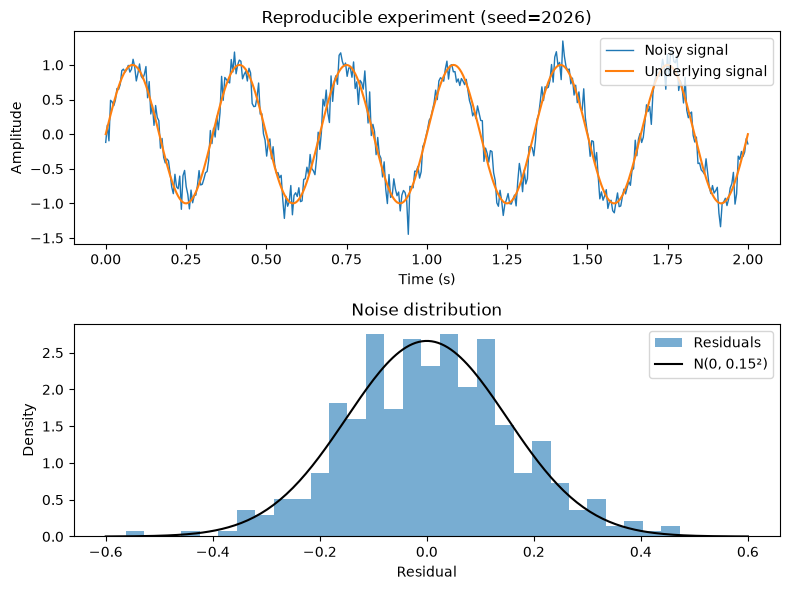

In [2]:
figure, axes = plt.subplots(2, 1, figsize=(8, 6))
axes[0].plot(time, signal, linewidth=1, label="Noisy signal")
axes[0].plot(time, clean, label="Underlying signal")
axes[0].set(xlabel="Time (s)", ylabel="Amplitude", title=f"Reproducible experiment (seed={SEED})")
axes[0].legend(loc="upper right")

grid = np.linspace(-4 * NOISE_SD, 4 * NOISE_SD, 200)
density = np.exp(-(grid**2) / (2 * NOISE_SD**2)) / (NOISE_SD * np.sqrt(2 * np.pi))
axes[1].hist(residuals, bins=30, density=True, alpha=0.6, label="Residuals")
axes[1].plot(grid, density, color="black", label=f"N(0, {NOISE_SD}²)")
axes[1].set(xlabel="Residual", ylabel="Density", title="Noise distribution")
axes[1].legend()
save_figure(WEEK, figure, "signal.png")
save_data(WEEK, "signal.npz", time_s=time, signal=signal, seed=np.array(SEED))

## Validación

1. Repetir el experimento con la misma semilla debe producir **exactamente** los mismos datos.
2. Una semilla distinta debe producir datos distintos.
3. La desviación estándar de los residuos debe aproximarse a $\sigma = 0.15$.

In [3]:
_, _, repeated = noisy_sine(SEED)
_, _, other_seed = noisy_sine(SEED + 1)
estimated_sd = residuals.std(ddof=1)

assert np.array_equal(signal, repeated), "same seed must reproduce the data"
assert not np.array_equal(signal, other_seed), "a different seed should change the data"
assert abs(estimated_sd - NOISE_SD) < 0.02, estimated_sd
print(f"Same seed reproduces data: True; residual SD = {estimated_sd:.3f} (expected {NOISE_SD})")

Same seed reproduces data: True; residual SD = 0.156 (expected 0.15)


## Para tu entrega

- Cambia la semilla y comprueba que la figura cambia, pero no su descripción estadística.
- Calcula cuántos puntos hacen falta para estimar $\sigma$ con un error menor a 0.005.
- Registra en tu README: comando de ejecución, versión de Python, semilla y parámetros.